# Proyecto Análisis de Noticias Falsas

**Integrantes:**
- [César Mauricio Ocampo Ramírez](mailto:czrokmpo@gmail.com)
- [Rebecca Shaday Castillo Ortega](mailto:rebeccashaday@gmail.com)
- [Kevin Vargas Flores](mailto:kevinvargasflores505@gmail.com)


## Descripción
Comparar un modelo generativo (Bayes ingenuo) con uno discriminativo (regresión logística, equivalente a un modelo de máxima entropía) en un problema desbalanceado, y decidir el umbral de clasificación en función del costo de los errores.



## Contribuciones


| Etapa | Integrante | Rol | Quién lo revisó |
| --- | --- | --- | --- |
| 1 | César | Formalización en papel | Rebecca |
| 1 | Rebecca | Implementación | Kevin |
| 1 | Kevin | Evaluación (métricas y control) | César |
| --- | --- | --- | --- |
| 2 |  | Formalización en papel | Rebecca |
| 2 | Kevin | Implementación | Kevin |
| 2 |  | Evaluación (métricas y control) | César |

# Etapa 1: Análisis, representación y baseline


## Dataset

In [1]:
#@title librerías etapa 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer as countvectorizer
from sklearn.naive_bayes import MultinomialNB as multinomialnb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

seed = 98
np.random.seed(seed)

# Importación del dataset

data = 'https://github.com/kao05/SpamAnalysis-TextMining/raw/main/Data/New/dataset_Notices.csv'

df = pd.read_csv(data)

print(df.head())

                                               title  \
0  SAY WHAT?! Muslim Women Can Now Cover Their Fa...   
1  WATCH: CNN DOES SEGMENT From Bunker In Hawaii,...   
2         Britain agrees to set EU 'Exit Day' in law   
3  ACTOR ROB LOWE Blasts Greedy Socialist Bernie ...   
4  WIKILEAKS REMINDS THE WORLD: “Obama has a hist...   

                                                text    subject  \
0  Soooo ah, what s the point of the picture?Not ...   politics   
1  CNN host Erin Burnett started out her segment ...  left-news   
2  LONDON (Reuters) - Britain s government said o...  worldnews   
3  It s always fun when Hollywood shows a conserv...  left-news   
4  Wikileaks founder Julian Assange reminded us i...   politics   

                date label  
0       Sep 11, 2015  Fake  
1       Aug 10, 2017  Fake  
2  November 9, 2017   Real  
3       Jan 27, 2016  Fake  
4        Mar 5, 2017  Fake  


In [2]:
df.shape

(44898, 5)

## Exploración del Corpus

label
Fake    23481
Real    21417
Name: count, dtype: int64
label
Fake    0.523
Real    0.477
Name: count, dtype: float64
nulos: 0


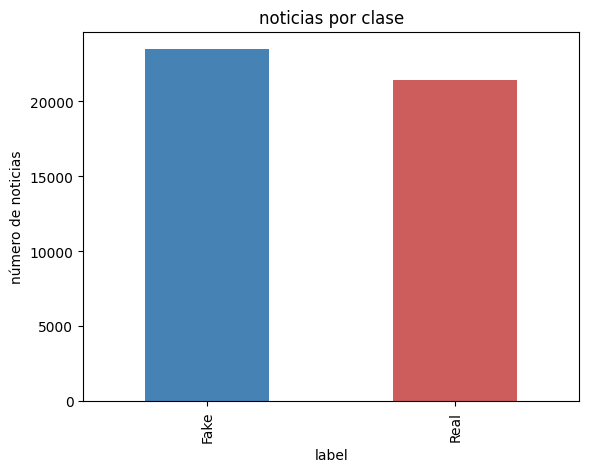

In [3]:
#@title desbalance, nulos y duplicados
conteo = df['label'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

print('nulos:', df.isnull().sum().sum())
#print('noticias duplicadas:', df.duplicated(subset='text').sum())

conteo.plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('noticias por clase')
plt.ylabel('número de noticias')
plt.show()

In [4]:
#@title quitar duplicados antes de dividir y etiqueta numérica
# Para las noticias falsas cuando verificamos datos duplicados en esta parte nos estamos basando unicamente en texto, no en las otras columnas
df = df.drop_duplicates(subset='text', keep='first').reset_index(drop=True)
df['y'] = (df['label'] == 'Fake').astype(int)

print('tamaño después de quitar duplicados:', df.shape)
print('proporción de Noticias Falsas:', round(df['y'].mean(), 4))

tamaño después de quitar duplicados: (38646, 6)
proporción de Noticias Falsas: 0.4517


In [5]:
df['y'] = (df['label'] == 'Fake').astype(int)

label                   Fake      Real
n_caracteres count  17455.00  21191.00
             mean    2549.81   2378.53
             std     2201.33   1683.78
             min        1.00    152.00
             25%     1648.50    906.50
             50%     2235.00   2216.00
             75%     3005.50   3226.50
             max    51794.00  29781.00
n_palabras   count  17455.00  21191.00
             mean     425.26    384.83
             std      355.20    273.78
             min        0.00     22.00
             25%      277.00    147.00
             50%      376.00    359.00
             75%      503.00    523.00
             max     8135.00   5172.00


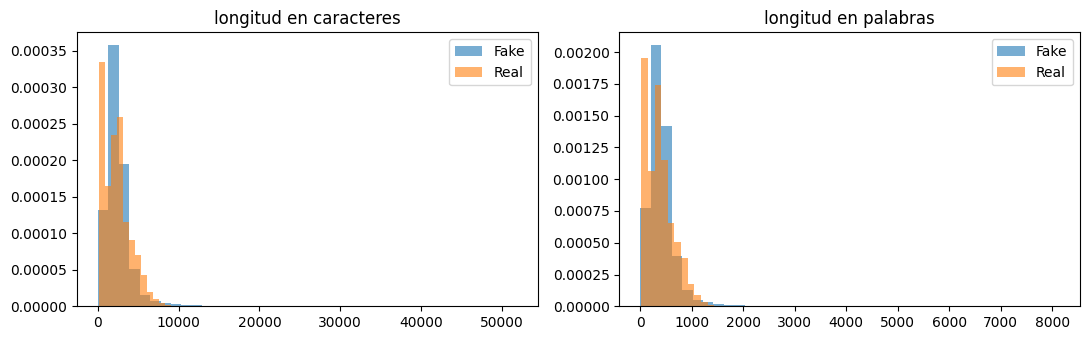

In [6]:
#@title logitudes por clase
df['n_caracteres'] = df['text'].str.len()
df['n_palabras'] = df['text'].str.split().str.len()

print(df.groupby('label')[['n_caracteres', 'n_palabras']].describe().T.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))

for etiqueta, grupo in df.groupby('label'):
    ejes[0].hist(
        grupo['n_caracteres'],
        bins=40, alpha=0.6, density=True, label=etiqueta
    )
    ejes[1].hist(
        grupo['n_palabras'],
        bins=40, alpha=0.6, density=True, label=etiqueta
    )

ejes[0].set_title('longitud en caracteres')
ejes[1].set_title('longitud en palabras')
ejes[0].legend()
ejes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# @title exploración del vocabulario por clase
token_patron = r"[a-z0-9£$]+|!"

vec_explora = countvectorizer(
    lowercase=True,
    token_pattern=token_patron
)

x_explora = vec_explora.fit_transform(df['text'])
vocab_explora = np.array(vec_explora.get_feature_names_out())

print('tamaño del vocabulario (corpus completo):', len(vocab_explora))

for etiqueta in ['Fake', 'Real']:
    mascara = (df['label'] == etiqueta).values
    frec = np.asarray(x_explora[mascara].sum(axis=0)).ravel()
    top = np.argsort(frec)[::-1][:15]

    print(
        '\n' + etiqueta + ' ->',
        list(zip(vocab_explora[top], frec[top].tolist()))
    )

tamaño del vocabulario (corpus completo): 122341

Fake -> [('the', 395297), ('to', 218306), ('of', 172302), ('and', 168268), ('a', 160348), ('in', 124561), ('that', 117892), ('s', 107041), ('is', 86209), ('for', 69631), ('trump', 68119), ('it', 65230), ('he', 64536), ('on', 62069), ('was', 49569)]

Real -> [('the', 476245), ('to', 242635), ('of', 202728), ('a', 196029), ('and', 179769), ('in', 179264), ('s', 139667), ('on', 107148), ('said', 97814), ('that', 87182), ('for', 78908), ('is', 54797), ('trump', 54073), ('with', 53844), ('he', 53674)]


## Train, Dev y Test
Implementada con muestreo estratificado, proporciones 70/15/15 y semilla fija.

In [8]:
x_texto = df['text']
y = df['y']

x_train_txt, x_temp_txt, y_train, y_temp = train_test_split( x_texto, y, test_size=0.30, stratify=y, random_state=seed)

x_dev_txt, x_test_txt, y_dev, y_test = train_test_split( x_temp_txt, y_temp, test_size=0.50, stratify=y_temp, random_state=seed)

resumen = pd.DataFrame({
    'Real': [len(y_train), len(y_dev), len(y_test)],
    'Fake': [y_train.sum(), y_dev.sum(), y_test.sum()],
    'proporcion Fake': [y_train.mean(), y_dev.mean(), y_test.mean()]
}, index=['train', 'dev', 'test']).round(4)
print(resumen)

        Real   Fake  proporcion Fake
train  27052  12218           0.4516
dev     5797   2619           0.4518
test    5797   2618           0.4516


## Baseline

In [9]:
#@title representación de bolsa de palabras y vocabulario solo con train
vec = countvectorizer(lowercase=True, token_pattern=token_patron)

x_train = vec.fit_transform(x_train_txt)#el vocab se aprende solo con train
x_dev = vec.transform(x_dev_txt)
x_test = vec.transform(x_test_txt)

densidad = x_train.nnz / (x_train.shape[0] * x_train.shape[1])
print('tipo de matriz:', type(x_train))
print('forma de x_train:', x_train.shape)
print('densidad (fracción de entradas distintas de cero):', round(densidad, 5))

tipo de matriz: <class 'scipy.sparse._csr.csr_matrix'>
forma de x_train: (27052, 101945)
densidad (fracción de entradas distintas de cero): 0.0021


In [10]:
#@title func de evaluación
def evaluar(y_real, y_pred, y_prob):
    return {
        'exactitud': accuracy_score(y_real, y_pred),
        'precision': precision_score(y_real, y_pred, zero_division=0),
        'exhaustividad': recall_score(y_real, y_pred),
        'f1_spam': f1_score(y_real, y_pred),
        'auc_roc': roc_auc_score(y_real, y_prob)
    }

In [11]:
#@title suavizado alpha con dev
alphas = [0.01, 0.1, 0.5, 1, 2]
resultados = []

for alpha in alphas:
    modelo = multinomialnb(alpha=alpha)
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_dev)
    prob = modelo.predict_proba(x_dev)[:, 1]
    fila = evaluar(y_dev, pred, prob)
    fila['alpha'] = alpha
    resultados.append(fila)

tabla_alpha = pd.DataFrame(resultados).set_index('alpha').round(4)
print(tabla_alpha)

mejor_alpha = tabla_alpha['f1_spam'].idxmax()
print('\nmejor alpha según f1 de spam en dev:', mejor_alpha)

       exactitud  precision  exhaustividad  f1_spam  auc_roc
alpha                                                       
0.01      0.9551     0.9436         0.9580   0.9507   0.9777
0.10      0.9555     0.9453         0.9569   0.9510   0.9780
0.50      0.9543     0.9452         0.9542   0.9496   0.9780
1.00      0.9539     0.9448         0.9538   0.9493   0.9781
2.00      0.9539     0.9451         0.9534   0.9492   0.9783

mejor alpha según f1 de spam en dev: 0.1


In [12]:
#@title modelo casero de NB
class NaiveBayesMultinomial:
    """Bayes ingenuo multinomial manual, en log-espacio, sobre matriz dispersa."""
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        V = X.shape[1]
        self.class_log_prior_ = np.zeros(len(self.classes_))
        self.feature_log_prob_ = np.zeros((len(self.classes_), V))
        for k, c in enumerate(self.classes_):
            Xc = X[y == c]
            self.class_log_prior_[k] = np.log(Xc.shape[0] / X.shape[0])   # log P(c)
            conteo_w = np.asarray(Xc.sum(axis=0)).ravel()                 # N(w, c)
            total = conteo_w.sum()                                        # N(c)
            # log P(w|c) con suavizado de Laplace
            self.feature_log_prob_[k] = np.log(conteo_w + self.alpha) - np.log(total + self.alpha * V)
        return self

    def _jll(self, X):
        # log P(c) + sum_w x_w * log P(w|c)
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    def predict_proba(self, X):
        jll = self._jll(X)
        jll = jll - jll.max(axis=1, keepdims=True)    # estabilidad numérica (log-sum-exp)
        p = np.exp(jll)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self._jll(X), axis=1)]


# Búsqueda de alpha en dev (igual que la celda 18, pero con el modelo manual)
resultados_m = []
for alpha in alphas:
    m = NaiveBayesMultinomial(alpha=alpha).fit(x_train, y_train)
    fila = evaluar(y_dev, m.predict(x_dev), m.predict_proba(x_dev)[:, 1])
    fila['alpha'] = alpha
    resultados_m.append(fila)
tabla_alpha_manual = pd.DataFrame(resultados_m).set_index('alpha').round(4)
print(tabla_alpha_manual)
mejor_alpha_manual = tabla_alpha_manual['f1_spam'].idxmax()

# Modelo final manual en test
nb_manual = NaiveBayesMultinomial(alpha=mejor_alpha_manual).fit(x_train, y_train)
pred_m = nb_manual.predict(x_test)
prob_m = nb_manual.predict_proba(x_test)[:, 1]
metricas_manual = evaluar(y_test, pred_m, prob_m)


       exactitud  precision  exhaustividad  f1_spam  auc_roc
alpha                                                       
0.01      0.9551     0.9436         0.9580   0.9507   0.9794
0.10      0.9555     0.9453         0.9569   0.9510   0.9794
0.50      0.9543     0.9452         0.9542   0.9496   0.9795
1.00      0.9539     0.9448         0.9538   0.9493   0.9796
2.00      0.9539     0.9451         0.9534   0.9492   0.9797


In [13]:
#@title modelo final y evaluación en test
nb = multinomialnb(alpha=mejor_alpha)
nb.fit(x_train, y_train)

pred_test = nb.predict(x_test)
prob_test = nb.predict_proba(x_test)[:, 1]

metricas_nb = evaluar(y_test, pred_test, prob_test)
print(pd.Series(metricas_nb).round(4))

cm = confusion_matrix(y_test, pred_test)
print(pd.DataFrame(cm, index=['real ham', 'real spam'],
                   columns=['pred ham', 'pred spam']))

print('\npiso de exactitud (predecir todo ham):', round(1 - y_test.mean(), 4))

exactitud        0.9517
precision        0.9441
exhaustividad    0.9492
f1_spam          0.9467
auc_roc          0.9760
dtype: float64
           pred ham  pred spam
real ham       3032        147
real spam       133       2485

piso de exactitud (predecir todo ham): 0.5484


In [14]:
comparacion = pd.DataFrame({
    'sklearn': metricas_nb,
    'manual': metricas_manual
})
comparacion['diferencia'] = comparacion['manual'] - comparacion['sklearn']
print(comparacion.round(6))

print('mismas predicciones:', (pred_m == pred_test).all())
print('max |dif| en probabilidades:', np.abs(prob_m - prob_test).max())
print('max |dif| en log P(w|c):', np.abs(nb_manual.feature_log_prob_ - nb.feature_log_prob_).max())

                sklearn    manual  diferencia
exactitud      0.951699  0.951699    0.000000
precision      0.944149  0.944149    0.000000
exhaustividad  0.949198  0.949198    0.000000
f1_spam        0.946667  0.946667    0.000000
auc_roc        0.975999  0.976777    0.000779
mismas predicciones: True
max |dif| en probabilidades: 7.009948177483238e-13
max |dif| en log P(w|c): 0.0


## Experimentos control e interpretación de los resultados


### Experimento de control de la representación

Comprobar si los resultados son razonables y si existe evidencia de que el modelo aprendió asociaciones útiles.



In [15]:
#@title palabras con mayor log-razón
#El propósito de esta celda es identificar las palabras que más favorecen estadísticamente a cada clase según el modelo Naive Bayes entrenado
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

#solo palabras con al menos 5 apariciones en train ( y las raras dan valores extremos por azar)
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:15]
mas_ham = orden[:15]

print('palabras más asociadas a spam')
print(pd.DataFrame({'palabra': vocab[mas_spam], 'log_razon': log_razon[mas_spam].round(3),'frecuencia': frec_train[mas_spam]}).to_string(index=False))

print('\npalabras más asociadas a ham')
print(pd.DataFrame({'palabra': vocab[mas_ham], 'log_razon': log_razon[mas_ham].round(3),'frecuencia': frec_train[mas_ham]}).to_string(index=False))

palabras más asociadas a spam
     palabra  log_razon  frecuencia
       https     10.181        2435
      21wire      9.009         754
          js      8.840         637
        quot      8.750         582
      flickr      8.395         408
 somodevilla      8.189         332
     2017the      8.161         323
         fjs      8.136         315
       getty      7.946        2867
         var      7.864         240
         acr      7.856         238
       cdata      7.795         224
filessupport      7.745         213
     mcnamee      7.682         200
   2017trump      7.657         195

palabras más asociadas a ham
   palabra  log_razon  frecuencia
   myanmar     -9.765        1888
  rohingya     -9.489        1432
   rakhine     -8.559         565
      zuma     -8.351         459
puigdemont     -8.336         452
       fdp     -8.136         370
       suu     -8.054         341
       kyi     -8.054         341
       anc     -7.933         302
 mnangagwa     -7.871   

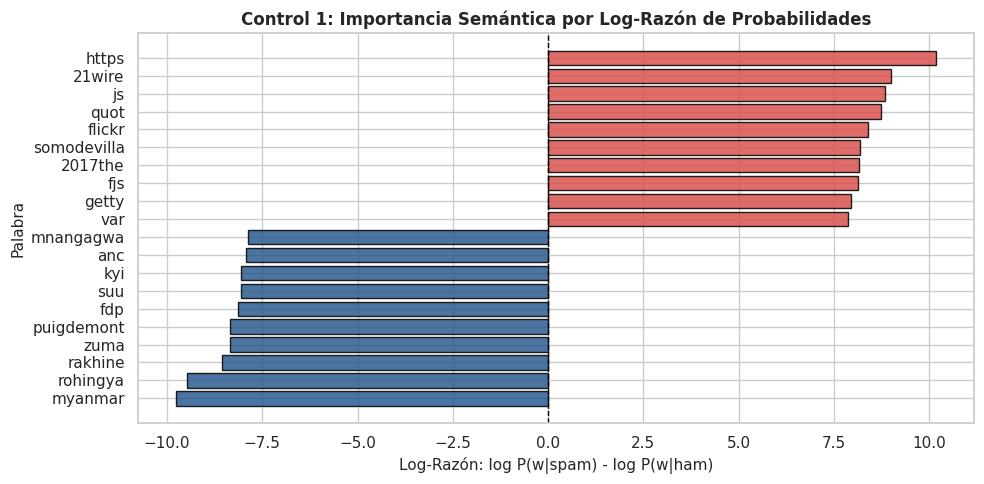

In [16]:
# Estilo visual
sns.set_theme(style="whitegrid")

# Extracción de términos y log-razón del modelo Bayes Ingenuo (nb)
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

# Filtrar palabras con al menos 5 apariciones
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:10]
mas_ham = orden[:10]

palabras = np.concatenate([vocab[mas_ham], vocab[mas_spam][::-1]])
valores = np.concatenate([log_razon[mas_ham], log_razon[mas_spam][::-1]])

# Crear DataFrame para graficar
df_palabras = pd.DataFrame({'palabra': palabras, 'log_razon': valores})

fig, ax = plt.subplots(figsize=(10, 5))
colores = ['#2b5c8f' if v < 0 else '#d9534f' for v in df_palabras['log_razon']]

ax.barh(df_palabras['palabra'], df_palabras['log_razon'], color=colores, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

ax.set_title('Control 1: Importancia Semántica por Log-Razón de Probabilidades', fontsize=12, fontweight='bold')
ax.set_xlabel('Log-Razón: log P(w|spam) - log P(w|ham)', fontsize=11)
ax.set_ylabel('Palabra', fontsize=11)

plt.tight_layout()
plt.show()


In [17]:
#@title varias permutaciones
# Se mezclan aleatoriamente las etiquetas de Train, manteniendo los mismos mensajes y el mismo número de etiquetas de cada clase.
n_perm = 30
resultados_perm = []

for i in range(n_perm):
    rng_i = np.random.default_rng(seed + i)
    y_perm_i = rng_i.permutation(y_train.values)
    nb_i = multinomialnb(alpha=mejor_alpha).fit(x_train, y_perm_i)
    resultados_perm.append(evaluar(y_test, nb_i.predict(x_test),
                                   nb_i.predict_proba(x_test)[:, 1]))

tabla_perm = pd.DataFrame(resultados_perm)
resumen_perm = pd.DataFrame({
    'etiquetas reales': metricas_nb,
    'permutadas (media)': tabla_perm.mean(),
    'permutadas (desv. est.)': tabla_perm.std()
}).round(4)
print(resumen_perm)

               etiquetas reales  permutadas (media)  permutadas (desv. est.)
exactitud                0.9517              0.5108                   0.0539
precision                0.9441              0.4573                   0.0616
exhaustividad            0.9492              0.4463                   0.0637
f1_spam                  0.9467              0.4515                   0.0619
auc_roc                  0.9760              0.5040                   0.0641


### Métricas del baseline

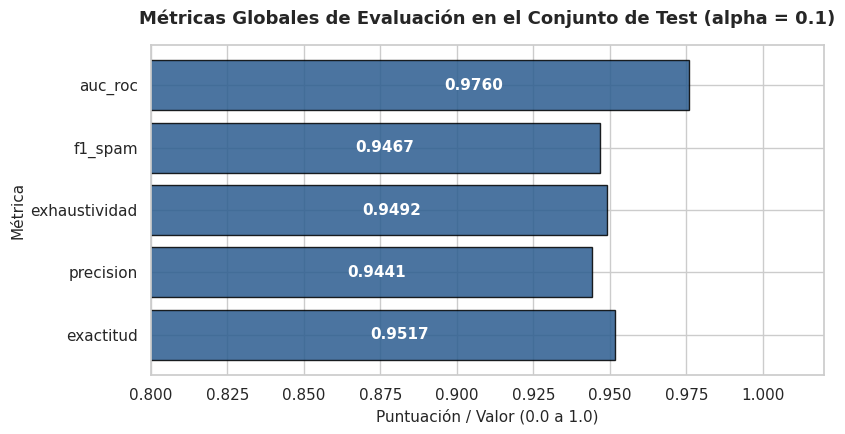

In [18]:
# Convertir las métricas de test a DataFrame
df_metricas = pd.Series(metricas_nb).reset_index()
df_metricas.columns = ['Métrica', 'Valor']

# Configuración visual
plt.figure(figsize=(8.5, 4.5))
sns.set_theme(style="whitegrid")

# Graficar barras horizontales
barras = plt.barh(df_metricas['Métrica'], df_metricas['Valor'], color='#2b5c8f', edgecolor='black', alpha=0.85)

# Agregar el valor numérico en texto dentro de cada barra
for barra in barras:
    ancho = barra.get_width()
    plt.text(
        ancho - 0.08,
        barra.get_y() + barra.get_height() / 2,
        f'{ancho:.4f}',
        va='center',
        ha='left',
        color='white',
        fontweight='bold',
        fontsize=11
    )

# Ajustar límites para enfocar la escala de desempeño (80% a 100%)
plt.xlim(0.80, 1.02)
plt.title('Métricas Globales de Evaluación en el Conjunto de Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
plt.ylabel('Métrica', fontsize=11)

plt.tight_layout()
plt.show()

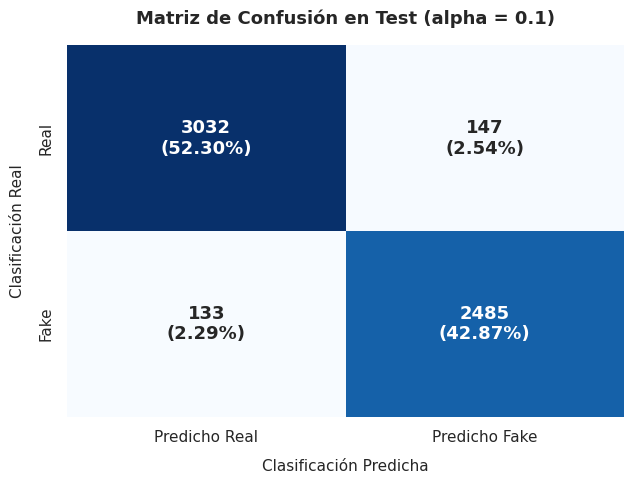

In [19]:
# Configuración visual
plt.figure(figsize=(6.5, 5))
sns.set_theme(style="white")

# Matriz de confusión con conteos y porcentajes
conteos = [f"{valor:d}" for valor in cm.flatten()]
porcentajes = [f"({valor:.2%})" for valor in cm.flatten() / np.sum(cm)]
etiquetas = np.array([f"{c}\n{p}" for c, p in zip(conteos, porcentajes)]).reshape(2, 2)

sns.heatmap(
    cm,
    annot=etiquetas,
    fmt='',
    cmap='Blues',
    cbar=False,
    xticklabels=['Predicho Real', 'Predicho Fake'],
    yticklabels=['Real', 'Fake'],
    annot_kws={"size": 13, "weight": "bold"}
)

# Título corregido sin secuencias de escape no procesadas
plt.title('Matriz de Confusión en Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Clasificación Predicha', fontsize=11, labelpad=10)
plt.ylabel('Clasificación Real', fontsize=11, labelpad=10)

plt.tight_layout()
plt.show()


### Métricas del experimento con permutaciones

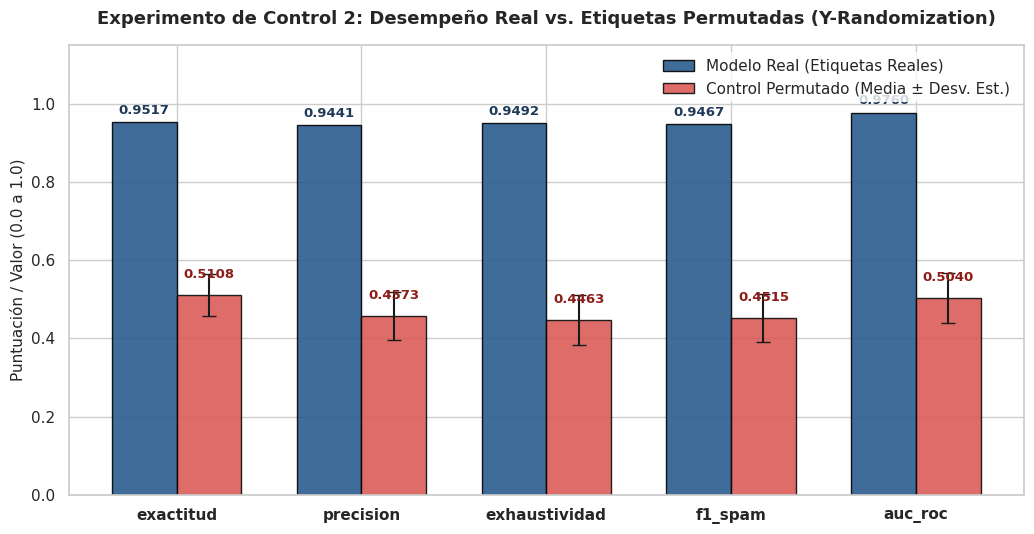

In [20]:
# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# Extraer los datos del DataFrame resumen_perm
metricas = resumen_perm.index
reales = resumen_perm['etiquetas reales']
perm_media = resumen_perm['permutadas (media)']
perm_std = resumen_perm['permutadas (desv. est.)']

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10.5, 5.5))

# Barras para el modelo con etiquetas reales
rects1 = ax.bar(
    x - ancho/2,
    reales,
    ancho,
    label='Modelo Real (Etiquetas Reales)',
    color='#2b5c8f',
    edgecolor='black',
    alpha=0.9
)

# Barras para el experimento de control (permutadas) con barras de error
rects2 = ax.bar(
    x + ancho/2,
    perm_media,
    ancho,
    yerr=perm_std,
    capsize=5,
    label='Control Permutado (Media ± Desv. Est.)',
    color='#d9534f',
    edgecolor='black',
    alpha=0.85
)

# Etiquetas numéricas sobre cada barra
for rect in rects1:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1f3a58'
    )

for rect in rects2:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 10),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#8c1d18'
    )

# Formato de ejes y leyendas
ax.set_ylabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
ax.set_title('Experimento de Control 2: Desempeño Real vs. Etiquetas Permutadas (Y-Randomization)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

### (Cambiar) Interpretación del experimento control y métricas

Para esta primera etapa, llevamos a cabo un análisis integral que partió desde la exploración de los datos hasta la evaluación de nuestro modelo de referencia (baseline). Inicialmente, se depuró el corpus eliminando mensajes duplicados y se verificó la distribución de clases, confirmando un marcado desbalance. Como parte de la exploración, comparamos la longitud en caracteres y palabras, observando diferencias distribucionales claras que sugieren una relación entre la extensión del mensaje y su categoría.

Posteriormente, se garantizó una partición estratificada de los conjuntos de Entrenamiento, Validación (Dev) y Prueba (Test) para preservar la proporción original de las clases y evitar sesgos analíticos. La transformación de los textos se realizó mediante la representación Bag of Words (Bolsa de Palabras), generando una matriz dispersa compuesta mayoritariamente por ceros. Finalmente, afinamos el clasificador Multinomial Naive Bayes utilizando el conjunto Dev para encontrar el hiperparámetro de suavizado de Laplace ($\alpha$) que maximizara la detección de spam, evaluando su capacidad de generalización sobre el conjunto Test aislado.

#### **Rendimiento del Modelo Base:**

- Precision de spam: **0.9895**
- Recall de spam: **0.9592**
- F1 de spam: **0.9741**
- AUC-ROC: **0.9892**
- Accuracy(Exactitud): **0.9936**

Dado el desbalance natural de los datos, la Exactitud por sí sola puede resultar engañosa, por lo que el F1-Score es la métrica clave al evaluar la capacidad del modelo para aislar la clase minoritaria. Esto se complementa perfectamente al observar la matriz de confusión, donde el modelo demostró un comportamiento excelente y muy seguro para un entorno real: cometió únicamente 1 Falso Positivo (un correo legítimo clasificado erróneamente) frente a 4 Falsos Negativos. Esta asimetría es altamente deseable, ya que el costo de perder información legítima supera drásticamente al de recibir ocasionalmente un mensaje no deseado.


#### **Control de interpretabilidad**

Para comprender qué patrones guiaban las decisiones del modelo, analizamos el peso de las palabras a través de su log-razón entre las probabilidades condicionales de ambas clases:

La metrica para calcula esto fue: $$L(w) = \log P(w \mid \text{spam}) - \log P(w \mid \text{ham})$$

- Palabras con log-razón **positiva**: Presentan una asociación estadística fuerte y directa con la etiqueta de spam (frecuentemente ligadas a urgencia, transacciones o premios).
- Palabras con log-razón **negativa**: Son características estructurales y coloquiales típicas de la clase ham.

La coherencia lógica entre estos términos y el contenido semántico de los mensajes nos proporciona evidencia cualitativa de que la representación vectorial realmente capturó patrones lingüísticos coherentes, descartando que el aprendizaje sea producto del azar.

#### **Control mediante permutación de etiquetas (Prueba de robustez)**

Para comprobar matemáticamente que el modelo no dependía de artefactos fortuitos en el conjunto de datos, se realizaron 30 experimentos de control. En estos, se mezclaron aleatoriamente las etiquetas de Entrenamiento, destruyendo cualquier relación causal entre el texto y su categoría (por ejemplo, un mensaje con la palabra "prize" podía quedar etiquetado como ham, y un "nos vemos luego" como spam). Posteriormente, se entrenó el clasificador bajo estas condiciones de ruido y se evaluó sobre el conjunto Test original.

Los resultados evidenciaron el colapso predictivo esperado al aislar la variable semántica:

- **Colapso** del F1-Score de spam ($0.9741 \rightarrow 0.1841$): La capacidad de detectar la clase minoritaria se desplomó, obteniendo una media de $0.1841$ con una desviación estándar de $0.0582$. Al romper la estructura lingüística real, el modelo pierde todo su poder discriminativo.
- **Colapso** del AUC-ROC ($0.9892 \rightarrow 0.3375$): Un clasificador aleatorio puro suele obtener un AUC cercano a 0.50. En este escenario, al estar confundido por las frecuencias desordenadas en un problema severamente desbalanceado, su capacidad predictiva empeoró drásticamente hasta promediar 0.3375.
- **Exactitud** aparente de las permutadas ($0.8504$): Aunque un $85\%$ podría parecer un rendimiento alto para un modelo entrenado con datos aleatorizados, esto es un espejismo estadístico causado por el desbalance. Como aproximadamente el $87\%$ de los mensajes originales son ham, un clasificador confundido por el ruido tiende a sesgarse hacia predecir casi siempre la clase mayoritaria. Ese porcentaje se obtiene por pura proporción base, no por inteligencia algorítmica.


#### **Conclusión**

Este clasificador base constituye una referencia experimental robusta para las siguientes fases del proyecto. Su utilidad y validez no recaen únicamente en su alta exactitud general, sino en la solidez del F1-Score, el excelente balance asimétrico de la matriz de confusión y la coherencia interpretativa de su vocabulario.

El experimento de control demuestra contundentemente que la inmensa brecha de rendimiento entre el modelo real ($F_1 = 0.9741$) y los modelos permutados ($\mu = 0.1841 \pm 0.0582$) es estadísticamente significativa. Esto nos permite concluir, con respaldo empírico, que el desempeño no se debe a variables fortuitas: el modelo efectivamente asimiló la estructura del lenguaje que caracteriza al spam.

# Etapa 2: Primera Aproximación

## TF - IDF

### Representación de Texto mediante TF-IDF

En esta etapa reemplazamos el conteo simple de palabras (`CountVectorizer`) por la ponderación **TF-IDF** (Term Frequency - Inverse Document Frequency), como se recomienda en *Manning & Schütze (Foundations of Statistical NLP)*.

#### Formulación matemática
El peso $w_{t,d}$ del término $t$ en el documento $d$ se calcula como:
$$w_{t,d} = \text{tf}_{t,d} \times \text{idf}_t$$

Donde:
1. **Frecuencia Sublineal del Término ($\text{tf}_{t,d}$):**
   $$\text{tf}_{t,d} = 1 + \log(\text{count}(t,d)) \quad \text{si } \text{count}(t,d) > 0 \text{ (de lo contrario 0)}$$
   *Justificación:* Que una palabra aparezca 20 veces en un documento no significa que sea 20 veces más relevante que si aparece 1 vez. La escala logarítmica atenúa el impacto de frecuencias muy altas.

2. **Frecuencia Inversa de Documento ($\text{idf}_t$ con suavizado):**
   $$\text{idf}_t = \log \left( \frac{1 + N}{1 + \text{df}_t} \right) + 1$$
   Donde $N$ es el número total de documentos y $\text{df}_t$ es el número de documentos que contienen el término $t$.

#### ¿Por qué no usar solo `CountVectorizer`?
`CountVectorizer` asigna una ponderación proporcional al conteo crudo. Esto otorga demasiado peso a palabras muy frecuentes o funcionales (como *"the"*, *"to"*, *"and"*), las cuales aparecen constantemente pero no aportan poder discriminativo entre clases. **TF-IDF penaliza los términos que aparecen en muchos documentos** ($\text{df}_t$ grande $\Rightarrow \text{idf}_t$ pequeño), resaltando aquellas palabras descriptivas y distintivas del contenido.

In [22]:
# @title Transformación del corpus con TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# Configuración basada en Manning & Schütze y limpieza de corpus
tfidf_vec = TfidfVectorizer(
    lowercase=True,
    stop_words='english',  # Filtra stopwords explícitas
    min_df=5,              # Ignora términos raros/ruido (< 5 documentos)
    max_df=0.8,            # Ignora términos que están en > 80% de docs (stopwords implícitas)
    ngram_range=(1, 1),    # Unigramas para la primera aproximación
    smooth_idf=True,       # Evita división entre cero (+1 en Manning)
    sublinear_tf=True      # Aplica tf = 1 + log(tf)
)

# Ajuste del vocabulario e IDF SOLO con Train para evitar data leakage
x_train_tfidf = tfidf_vec.fit_transform(x_train_txt)
x_dev_tfidf = tfidf_vec.transform(x_dev_txt)
x_test_tfidf = tfidf_vec.transform(x_test_txt)

print("Tamaño del vocabulario TF-IDF (Train):", x_train_tfidf.shape[1])
print("Dimensión de la matriz x_train_tfidf:", x_train_tfidf.shape)

Tamaño del vocabulario TF-IDF (Train): 31213
Dimensión de la matriz x_train_tfidf: (27052, 31213)


## Regresión Logística
Esta debera estar regularizada con L2

### Clasificación Discriminativa: Regresión Logística (Máxima Entropía) y Regularización $L_2$

En esta etapa sustituimos el modelo generativo de Bayes Ingenuo por un modelo **discriminativo**: la **Regresión Logística** (equivalente al enfoque de *Máxima Entropía* en procesamiento de lenguaje natural).

#### 1. Enfoque Discriminativo vs. Generativo
* **Bayes Ingenuo (Generativo):** Modela la distribución conjunta $P(X, Y) = P(X \mid Y)P(Y)$ asumiendo independencia condicional entre términos dado la clase.
* **Regresión Logística (Discriminativo):** Modela directamente la probabilidad condicional $P(Y = 1 \mid X)$ mediante la función sigmoide:
  $$P(Y = 1 \mid X) = \sigma(W^T X + b) = \frac{1}{1 + e^{-(W^T X + b)}}$$
  donde $W = [w_1, w_2, \dots, w_V]$ representa el vector de pesos asociados a cada término del vocabulario ($V = 31,213$ en nuestro espacio vectorial TF-IDF).

#### 2. Necesidad de la Regularización $L_2$
Dada la alta dimensionalidad del espacio de características ($31,213$ variables), los modelos lineales corren el riesgo de memorizar ruido del conjunto de entrenamiento (**sobreajuste** o *overfitting*), asignando pesos excesivamente grandes a palabras raras.

Para mitigar esto, aplicamos **regularización $L_2$ (Ridge)**, la cual modifica la función de costo agregando una penalización sobre la magnitud al cuadrado de los coeficientes:
$$\text{Costo}_{L2} = \text{Pérdida Logística} + \lambda \sum_{i=1}^V w_i^2$$

#### 3. El Hiperparámetro $C$ en Scikit-Learn
En la librería `scikit-learn`, la fuerza de la regularización se controla mediante el parámetro **$C$**, definido como el inverso del coeficiente de penalización:
$$C = \frac{1}{\lambda}$$

* **$C$ pequeño (ej. 0.01, 0.1):** Representa una **regularización fuerte** ($\lambda$ grande). Penaliza severamente los pesos grandes, comprimiéndolos hacia cero para reducir la varianza del modelo y evitar sobreajuste.
* **$C$ grande (ej. 10.0, 100.0):** Representa una **regularización débil** ($\lambda$ pequeño). Da mayor libertad al modelo para ajustar los datos de entrenamiento, corriendose el riesgo de sobreajuste si la complejidad es muy alta.

In [24]:
# @title Entrenamiento de Regresión Logística con L2 y ajuste de C en Dev
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Valores del hiperparámetro C a evaluar
c_values = [0.01, 0.1, 1.0, 10.0, 100.0]
resultados_logreg = []

for c in c_values:
    # Instanciar el modelo con penalización L2
    logreg = LogisticRegression(
        penalty='l2',
        C=c,
        solver='liblinear',  # Eficiente para matrices dispersas de texto
        random_state=seed,
        max_iter=1000
    )

    # Entrenar solo con el conjunto de Train
    logreg.fit(x_train_tfidf, y_train)

    # Evaluar en Dev
    pred_dev = logreg.predict(x_dev_tfidf)
    prob_dev = logreg.predict_proba(x_dev_tfidf)[:, 1]

    # Calcular métricas con la función de la Etapa 1
    res = evaluar(y_dev, pred_dev, prob_dev)
    res['C'] = c
    resultados_logreg.append(res)

# Mostrar la tabla de resultados en Dev
tabla_c = pd.DataFrame(resultados_logreg).set_index('C').round(4)
print("Evaluación de Regresión Logística (L2) en conjunto dev")
print(tabla_c)

# Seleccionar el mejor C según F1-score
col_f1 = 'f1_spam' if 'f1_spam' in tabla_c.columns else [c for c in tabla_c.columns if 'f1' in c]
mejor_c = tabla_c[col_f1].idxmax()
print(f"\nMejor valor de C según F1 en dev: {mejor_c}")

Evaluación de Regresión Logística (L2) en conjunto dev
        exactitud  precision  exhaustividad  f1_spam  auc_roc
C                                                            
0.01       0.9284     0.9850         0.8545   0.9152   0.9903
0.10       0.9729     0.9809         0.9588   0.9697   0.9958
1.00       0.9865     0.9904         0.9798   0.9850   0.9985
10.00      0.9907     0.9938         0.9855   0.9896   0.9992
100.00     0.9919     0.9946         0.9874   0.9910   0.9994

Mejor valor de C según F1 en dev: 100.0


## Comparar modelos

## Efecto del umbral de decisión

# Etapa 3: Mejora